# Farmer, Wolf, Goat, and Cabbage Problem (DFS)

## 1. Problem Overview

The **Farmer, Wolf, Goat, and Cabbage** puzzle (also known as the *River Crossing Riddle*) is an ancient, world-famous mathematical riddle dating back to at least the 8th-century manuscript *Propositiones ad Acuendos Juvenes* (Problems to Sharpen the Young) attributed to Alcuin.

It serves as an introductory problem in Artificial Intelligence to understand **state space formulation**, **constraint satisfaction**, and **Depth-First Search (DFS)**.

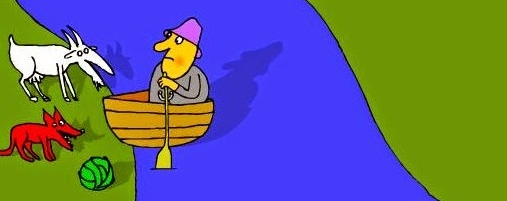

### Problem Statement

- A **farmer** arrives at the bank of a river with a **wolf**, a **goat**, and a **cabbage**.
- There is a small rowboat available, but it can carry **at most the farmer plus one item** (wolf, goat, or cabbage) at a time.
- Only the **farmer** knows how to row the boat (the boat cannot cross on its own).
- **Critical Safety Constraints:**
  - If the farmer leaves the **wolf and the goat** alone on either bank, the **wolf will eat the goat**.
  - If the farmer leaves the **goat and the cabbage** alone on either bank, the **goat will eat the cabbage**.
  - The wolf and the cabbage can safely be left alone together (wolves do not eat cabbage!).
- **Objective:** Find a sequence of safe boat crossings to transport the farmer, wolf, goat, and cabbage from the **left bank** to the **right bank** using **Depth-First Search (DFS)**.

### Learning Objectives

In this notebook, you will learn how to:
1. **Formulate the state space** as a 4-element binary tuple `(farmer, wolf, goat, cabbage)`.
2. **Implement safety rules** using a constraint-checking function (`is_valid`).
3. **Construct the state space graph** by systematically modeling all legal crossings.
4. **Apply Depth-First Search (DFS)** using a LIFO stack and cycle detection.
5. **Trace the DFS execution** step-by-step and understand the critical turning points of the puzzle.

## 2. State Space Representation & Constraints

### State Representation

We represent any configuration of the puzzle using a 4-element tuple of binary values:

$$\text{State} = (\text{farmer},\; \text{wolf},\; \text{goat},\; \text{cabbage})$$

Where each variable indicates which bank the entity currently occupies:
- `0`: The entity is on the **Left bank** (starting side).
- `1`: The entity is on the **Right bank** (target side).

### Initial and Goal States

- **Initial State:** `(0, 0, 0, 0)` — Farmer, wolf, goat, and cabbage are all on the left bank.
- **Goal State:** `(1, 1, 1, 1)` — All four entities have safely crossed to the right bank.

### Safety & Validity Constraints

A state is considered **valid (safe)** if and only if:
1. **Goat & Cabbage Safety:** The goat and cabbage are not on the same bank unless the farmer is also there to guard them:
   $$(\text{goat} == \text{cabbage}) \implies (\text{farmer} == \text{goat})$$
2. **Wolf & Goat Safety:** The wolf and goat are not on the same bank unless the farmer is also there to guard them:
   $$(\text{wolf} == \text{goat}) \implies (\text{farmer} == \text{goat})$$

> **Note:** When the farmer is present on a bank, all animals and food are under the farmer's direct supervision and no one is eaten.

In [1]:
def is_valid(state: tuple[int, int, int, int]) -> bool:
    farmer, wolf, goat, cabbage = state

    # Goat eats cabbage if farmer is absent
    if goat == cabbage and farmer != goat:
        return False

    # Wolf eats goat if farmer is absent
    if wolf == goat and farmer != goat:
        return False

    return True

### Valid vs. Invalid State Examples

Because each of the 4 entities can be on either of the 2 riverbanks, there are $2^4 = 16$ mathematically possible states.

Applying our constraints reveals that **10 states are valid** and **6 states are invalid**:

| State `(F, W, G, C)` | Left Bank | Right Bank | Status | Reason |
|:---:|:---:|:---:|:---:|:---|
| `(0, 0, 0, 0)` | F, W, G, C | *(Empty)* | **Valid** | Starting state; farmer is present on left bank. |
| `(1, 0, 1, 0)` | W, C | F, G | **Valid** | Wolf and cabbage alone on left (safe); farmer with goat on right. |
| `(0, 1, 1, 0)` | F, C | W, G | **Invalid** | Wolf and goat alone on right bank without farmer $\implies$ Wolf eats Goat! |
| `(0, 0, 1, 1)` | F, W | G, C | **Invalid** | Goat and cabbage alone on right bank without farmer $\implies$ Goat eats Cabbage! |
| `(1, 0, 0, 0)` | W, G, C | F | **Invalid** | Wolf, goat, and cabbage alone on left bank $\implies$ Wolf eats Goat, Goat eats Cabbage! |
| `(0, 1, 0, 1)` | F, G | W, C | **Valid** | Farmer guards goat on left; wolf and cabbage safe on right. |
| `(1, 1, 1, 1)` | *(Empty)* | F, W, G, C | **Valid** | Goal state; all entities have reached the right bank safely. |

## 3. Transition Rules & Graph Construction

### Allowed Boat Crossings

On every river crossing, the **farmer must be on the boat** to row it. In addition, the boat can carry at most one passenger/item. This gives 4 possible choices of passenger:

1. `item = 0`: Farmer rows **alone** (no passenger).
2. `item = 1`: Farmer takes the **Wolf**.
3. `item = 2`: Farmer takes the **Goat**.
4. `item = 3`: Farmer takes the **Cabbage**.

### Move Requirements

- **Farmer position flips:** $\text{farmer}_{\text{next}} = 1 - \text{farmer}$.
- **Item passenger check:** An item can only be transported if it is currently on the **same bank as the farmer** (`state[item] == farmer`).
- **Passenger position flips:** $\text{item}_{\text{next}} = 1 - \text{state}[\text{item}]$.
- **Safety validation:** The resulting state must satisfy `is_valid(next_state) == True`.

We construct the problem as an **Adjacency List** dictionary where each state maps to all valid, safe neighbor states.

In [2]:
from itertools import product

def build_graph() -> dict:
    states = [
        state
        for state in product(range(2), repeat=4)
        if is_valid(state)
    ]

    graph = {}

    for state in states:
        graph[state] = []
        farmer, wolf, goat, cabbage = state

        # Farmer crosses alone (item=0) or carries one item (item=1: Wolf, 2: Goat, 3: Cabbage)
        for item in range(4):
            next_state = list(state)

            # Farmer always crosses: 0 -> 1 or 1 -> 0
            next_state[0] = 1 - farmer

            # If carrying an item, it must be on the farmer's current bank
            if item != 0:
                if state[item] != farmer:
                    continue
                next_state[item] = 1 - state[item]

            next_state = tuple(next_state)

            # Add transition if the resulting state is safe and not duplicate
            if is_valid(next_state) and next_state not in graph[state]:
                graph[state].append(next_state)

    return graph

## 4. Depth-First Search (DFS) Implementation

### How DFS Works

**Depth-First Search (DFS)** is an unguided graph traversal algorithm that explores as deeply as possible along each branch before backtracking.

- **Data Structure:** Uses a **LIFO (Last In, First Out) Stack**.
- **Cycle Prevention:** A `visited` set ensures that states already evaluated are not re-expanded, preventing infinite back-and-forth loops across the river.
- **Exploration Order:** Neighbors are pushed to the stack using `reversed(...)`, ensuring that the first generated neighbor is positioned on top of the stack and popped first.

### Algorithm Steps

1. Initialize `stack = [[start]]` and `visited = set()`.
2. While the stack is not empty:
   - Pop the most recent path: `path = stack.pop()`.
   - Inspect the current node: `node = path[-1]`.
   - If `node in visited`, skip it (cycle detection).
   - Mark `node` as visited: `visited.add(node)`.
   - If `node == goal`, return `path` immediately!
   - For each neighbor in `reversed(graph.get(node, []))`:
     - If `neighbor not in visited`, push `path + [neighbor]` to `stack`.
3. If the stack becomes empty without reaching the goal, return `None`.

In [3]:
def dfs(graph: dict, start: tuple, goal: tuple) -> list | None:
    if start == goal:
        return [start]

    stack = [[start]]
    visited = set()

    while stack:
        path = stack.pop()
        node = path[-1]

        if node in visited:
            continue

        visited.add(node)

        if node == goal:
            return path

        # Push neighbors in reverse order so the first neighbor is explored first
        for neighbor in reversed(graph.get(node, [])):
            if neighbor not in visited:
                stack.append(path + [neighbor])

    return None

## 5. Running DFS & Finding the Solution

Now we construct the state space graph and execute Depth-First Search starting from `(0, 0, 0, 0)` with target `(1, 1, 1, 1)`.

We format the solution into a clear, structured table showing the contents of each bank and the action taken on every river crossing.

In [4]:
def print_state(state):
    names = ["Farmer", "Wolf", "Goat", "Cabbage"]

    left = [names[i] for i in range(4) if state[i] == 0]
    right = [names[i] for i in range(4) if state[i] == 1]

    print("Left bank: ", left)
    print("Right bank:", right)
    print()

In [5]:
graph = build_graph()

start = (0, 0, 0, 0)
goal  = (1, 1, 1, 1)

path  = dfs(graph, start, goal)

if path:
    for step, state in enumerate(path):
        print(f"Step {step}: {state}")
        print_state(state)
else:
    print("No solution found.")

Step 0: (0, 0, 0, 0)
Left bank:  ['Farmer', 'Wolf', 'Goat', 'Cabbage']
Right bank: []

Step 1: (1, 0, 1, 0)
Left bank:  ['Wolf', 'Cabbage']
Right bank: ['Farmer', 'Goat']

Step 2: (0, 0, 1, 0)
Left bank:  ['Farmer', 'Wolf', 'Cabbage']
Right bank: ['Goat']

Step 3: (1, 1, 1, 0)
Left bank:  ['Cabbage']
Right bank: ['Farmer', 'Wolf', 'Goat']

Step 4: (0, 1, 0, 0)
Left bank:  ['Farmer', 'Goat', 'Cabbage']
Right bank: ['Wolf']

Step 5: (1, 1, 0, 1)
Left bank:  ['Goat']
Right bank: ['Farmer', 'Wolf', 'Cabbage']

Step 6: (0, 1, 0, 1)
Left bank:  ['Farmer', 'Goat']
Right bank: ['Wolf', 'Cabbage']

Step 7: (1, 1, 1, 1)
Left bank:  []
Right bank: ['Farmer', 'Wolf', 'Goat', 'Cabbage']



## 6. Step-by-Step Execution & Tracing

To thoroughly understand how DFS navigates the state space and why this solution is safe, let's examine two detailed traces:
1. The **DFS Stack & Search Trace** (how the search algorithm expands nodes, uses the stack, and avoids cycles).
2. The **Physical River-Crossing Narrative** (how the farmer, animals, and cabbage move across the river safely).

---

### 6.1 DFS Search Stack & Frontier Trace

The table below records each iteration of the DFS `while stack:` loop:
- `Step`: The loop iteration number.
- `Popped State`: The state currently removed from the top of the stack (`path[-1]`).
- `Stack (Top -> Bottom)`: Active paths waiting on the LIFO stack.
- `Visited Set Size`: Number of unique states expanded.
- `Action / Observation`: Transition decisions and cycle pruning.

| Step | Popped State (`node`) | Current Path Length | Stack (Top $\to$ Bottom) | Visited Size | Action / Observation |
|:---:|:---:|:---:|:---|:---:|:---|
| **Initial** | — | — | `[(0, 0, 0, 0)]` | 0 | Starting path pushed to stack |
| **1** | `(0, 0, 0, 0)` | 1 | `[(1, 0, 1, 0)]` | 1 | Only legal first move is taking Goat! Wolf or Cabbage left behind would eat each other. |
| **2** | `(1, 0, 1, 0)` | 2 | `[(0, 0, 1, 0)]` | 2 | Taking Goat back returns to start (visited); Farmer must return alone. |
| **3** | `(0, 0, 1, 0)` | 3 | `[(1, 1, 1, 0), (1, 0, 1, 1)]` | 3 | Farmer can take Wolf or Cabbage across. Wolf branch `(1, 1, 1, 0)` is on top! |
| **4** | `(1, 1, 1, 0)` | 4 | `[(0, 1, 0, 0), (1, 0, 1, 1)]` | 4 | **Key Turning Point:** If farmer returns alone, Wolf eats Goat. Farmer MUST bring Goat back! |
| **5** | `(0, 1, 0, 0)` | 5 | `[(1, 1, 0, 1), (1, 0, 1, 1)]` | 5 | Farmer takes Cabbage across. Goat is left safely on left bank. |
| **6** | `(1, 1, 0, 1)` | 6 | `[(0, 1, 0, 1), (0, 0, 0, 1), (1, 0, 1, 1)]` | 6 | Wolf and Cabbage are safe together; Farmer returns alone to fetch Goat. |
| **7** | `(0, 1, 0, 1)` | 7 | `[(1, 1, 1, 1), (0, 0, 0, 1), (1, 0, 1, 1)]` | 7 | Farmer takes Goat across to right bank. Goal state pushed to top of stack! |
| **8** | **`(1, 1, 1, 1)`** | 8 | *Goal Reached!* | 8 | **Target state reached! DFS returns solution path.** |

---

### 6.2 Physical River-Crossing Narrative

Here is the detailed narrative of each crossing, explaining why no entity is eaten at any stage:

| Step | Action Taken | Left Bank | Boat | Right Bank | Why It Is Safe |
|:---:|:---|:---|:---:|:---|:---|
| **0** | *Starting position* | **Farmer, Wolf, Goat, Cabbage** | **Left** | *(Empty)* | All entities start together on the left bank. |
| **1** | Farmer takes **Goat** across (L $\to$ R) | **Wolf, Cabbage** | **Right** | **Farmer, Goat** | Wolf does not eat Cabbage; Farmer supervises Goat. |
| **2** | Farmer rows **alone** back (R $\to$ L) | **Farmer, Wolf, Cabbage** | **Left** | **Goat** | Goat is alone on right bank (safe). |
| **3** | Farmer takes **Wolf** across (L $\to$ R) | **Cabbage** | **Right** | **Farmer, Wolf, Goat** | Cabbage is alone on left bank; Farmer supervises Wolf and Goat. |
| **4** | **Farmer takes Goat back (R $\to$ L)** | **Farmer, Goat, Cabbage** | **Left** | **Wolf** | **Critical maneuver:** Prevents Wolf from eating Goat. Wolf is left alone on right bank. |
| **5** | Farmer takes **Cabbage** across (L $\to$ R) | **Goat** | **Right** | **Farmer, Wolf, Cabbage** | Goat is alone on left bank; Wolf and Cabbage do not harm each other. |
| **6** | Farmer rows **alone** back (R $\to$ L) | **Farmer, Goat** | **Left** | **Wolf, Cabbage** | Wolf and Cabbage remain safe together on right bank. |
| **7** | Farmer takes **Goat** across (L $\to$ R) | *(Empty)* | **Right** | **Farmer, Wolf, Goat, Cabbage** | **Goal reached!** Everyone has crossed the river safely. |

## 7. Complexity Analysis

### State Space & Graph Properties

- **Total Theoretical States:** $2^4 = 16$ binary configurations.
- **Valid States ($|V|$):** Exactly $10$ states satisfy all safety constraints.
- **Directed Edges ($|E|$):** $20$ legal directed transitions (10 bidirectional pairs).
- **Branching Factor ($b$):** Between $1$ and $3$ valid actions per state.

### Time Complexity

- Standard DFS visiting vertices and edges runs in **$\mathcal{O}(|V| + |E|)$** time.
- With full path storage in the stack:
  $$\text{Time Complexity} = \mathcal{O}(|V|^2 + |E|)$$
- With only 10 valid states, DFS reaches the goal in **8 steps**, executing in less than **1 millisecond**.

### Space Complexity

- **Stack Space:** Stores the current exploration branch. In this problem, the maximum stack size never exceeds **3 paths**.
- **Visited Set:** Stores at most $|V|$ states: **$\mathcal{O}(|V|)$**.
- Overall auxiliary memory is bounded by **$\mathcal{O}(|V|)$**.

### DFS vs. BFS on River-Crossing Problems

| Feature | Breadth-First Search (BFS) | Depth-First Search (DFS) |
|:---|:---|:---|
| **Data Structure** | FIFO Queue (`deque`) | LIFO Stack (`list`) |
| **Exploration Style** | Level-by-level | Branch-by-branch (deepest first) |
| **Optimality** | Guaranteed shortest path (7 crossings) | Not guaranteed in general; finds 7 crossings here due to graph structure |
| **Memory Consumption** | Higher (stores entire current frontier) | Lower (stores only current branch) |
| **Cycle Vulnerability** | Cycles cause redundant states | Cycles cause infinite loops without a `visited` set |